<a href="https://colab.research.google.com/github/Stongef/DL-1/blob/main/mnist_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MNIST ile MLP Tabanlı El Yazısı Rakam Tanıma
**Ad Soyad:** ...  **Öğrenci No:** ...

Colab'da önce `Çalışma zamanı > Çalışma zamanı türünü değiştir > GPU` seçebilirsin (zorunlu değil, MLP CPU'da da hızlı).
Hücreleri sırayla çalıştır.

## 1. Kurulum ve Hiperparametreler

In [1]:
import os, time, json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from PIL import Image

CONFIG = dict(
    seed=42,
    hidden=(256, 128),   # 2 hidden layer
    activation="ReLU",
    optimizer="Adam",
    lr=1e-3,
    batch_size=128,
    epochs=15,
    train_size=55000,
    val_size=5000,
)
MNIST_MEAN, MNIST_STD = 0.1307, 0.3081

torch.manual_seed(CONFIG["seed"])
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("results", exist_ok=True)
print("Cihaz:", device)
print(CONFIG)

Cihaz: cuda
{'seed': 42, 'hidden': (256, 128), 'activation': 'ReLU', 'optimizer': 'Adam', 'lr': 0.001, 'batch_size': 128, 'epochs': 15, 'train_size': 55000, 'val_size': 5000}


## 2. Veri: Train / Validation / Test ayrımı

100%|██████████| 9.91M/9.91M [00:00<00:00, 11.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 354kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.29MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.2MB/s]


Train: 55000 | Validation: 5000 | Test: 10000


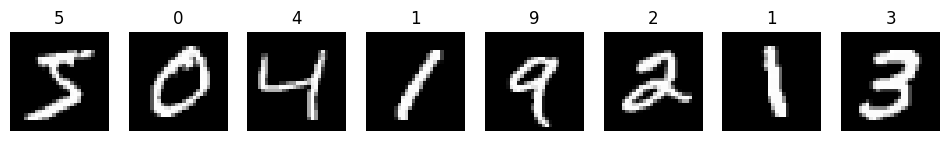

In [2]:
tf = transforms.Compose([transforms.ToTensor(),
                         transforms.Normalize((MNIST_MEAN,), (MNIST_STD,))])
full_train = datasets.MNIST("data", train=True, download=True, transform=tf)
test_set   = datasets.MNIST("data", train=False, download=True, transform=tf)

train_set, val_set = random_split(
    full_train, [CONFIG["train_size"], CONFIG["val_size"]],
    generator=torch.Generator().manual_seed(CONFIG["seed"]))

print(f"Train: {len(train_set)} | Validation: {len(val_set)} | Test: {len(test_set)}")

train_loader = DataLoader(train_set, batch_size=CONFIG["batch_size"], shuffle=True)
val_loader   = DataLoader(val_set, batch_size=1000)
test_loader  = DataLoader(test_set, batch_size=1000)

# Birkaç örnek görelim
fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for i, a in enumerate(ax):
    img, lbl = full_train[i]
    a.imshow(img.squeeze(), cmap="gray"); a.set_title(lbl); a.axis("off")
plt.show()

## 3. Model (MLP, CNN yok)

In [3]:
class MLP(nn.Module):
    def __init__(self, hidden=(256, 128)):
        super().__init__()
        layers, prev = [nn.Flatten()], 28 * 28
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, 10))   # softmax CrossEntropyLoss icinde
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

model = MLP(CONFIG["hidden"]).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["lr"])
print(model)
print("Parametre sayisi:", sum(p.numel() for p in model.parameters()))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parametre sayisi: 235146


## 4. Eğitim

In [4]:
def run_epoch(model, loader, train=False):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
best_val_acc, best_state = 0.0, None

start = time.time()
for ep in range(1, CONFIG["epochs"] + 1):
    tl, ta = run_epoch(model, train_loader, train=True)
    vl, va = run_epoch(model, val_loader)
    for k, v in zip(hist, [tl, vl, ta, va]):
        hist[k].append(v)
    if va > best_val_acc:               # model secimi SADECE validation ile
        best_val_acc = va
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    print(f"Epoch {ep:2d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
train_time = time.time() - start
print(f"\nEgitim suresi: {train_time:.1f} sn")

Epoch  1 | train loss 0.2875 acc 0.9151 | val loss 0.1541 acc 0.9512
Epoch  2 | train loss 0.1099 acc 0.9664 | val loss 0.1115 acc 0.9660
Epoch  3 | train loss 0.0720 acc 0.9775 | val loss 0.0886 acc 0.9722
Epoch  4 | train loss 0.0546 acc 0.9827 | val loss 0.0895 acc 0.9710
Epoch  5 | train loss 0.0414 acc 0.9865 | val loss 0.0810 acc 0.9740
Epoch  6 | train loss 0.0323 acc 0.9891 | val loss 0.0932 acc 0.9730
Epoch  7 | train loss 0.0275 acc 0.9914 | val loss 0.0859 acc 0.9786
Epoch  8 | train loss 0.0241 acc 0.9922 | val loss 0.0896 acc 0.9762
Epoch  9 | train loss 0.0186 acc 0.9934 | val loss 0.0824 acc 0.9774
Epoch 10 | train loss 0.0161 acc 0.9946 | val loss 0.0827 acc 0.9778
Epoch 11 | train loss 0.0182 acc 0.9937 | val loss 0.0992 acc 0.9748
Epoch 12 | train loss 0.0159 acc 0.9949 | val loss 0.0917 acc 0.9772
Epoch 13 | train loss 0.0130 acc 0.9957 | val loss 0.1112 acc 0.9748
Epoch 14 | train loss 0.0113 acc 0.9963 | val loss 0.1083 acc 0.9750
Epoch 15 | train loss 0.0145 acc 0

## 5. Grafikler

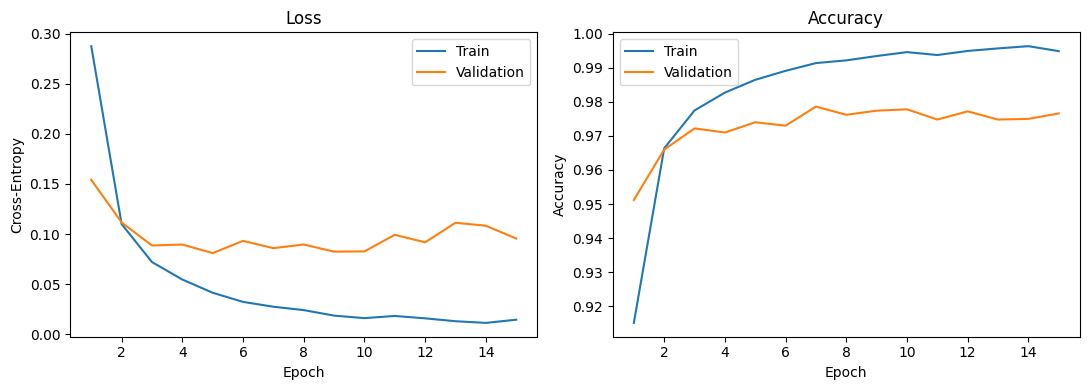

In [5]:
ep = range(1, CONFIG["epochs"] + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, hist["train_loss"], label="Train"); ax[0].plot(ep, hist["val_loss"], label="Validation")
ax[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-Entropy"); ax[0].legend()
ax[1].plot(ep, hist["train_acc"], label="Train"); ax[1].plot(ep, hist["val_acc"], label="Validation")
ax[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
plt.tight_layout(); plt.savefig("results/training_curves.png", dpi=150); plt.show()

## 6. Test (yalnızca en sonda, bir kez)

In [6]:
model.load_state_dict(best_state)       # validation'a gore en iyi epoch
test_loss, test_acc = run_epoch(model, test_loader)

print(f"Training loss       : {hist['train_loss'][-1]:.4f}")
print(f"Validation loss     : {hist['val_loss'][-1]:.4f}")
print(f"Training accuracy   : {hist['train_acc'][-1]:.4f}")
print(f"Validation accuracy : {hist['val_acc'][-1]:.4f}")
print(f"Test accuracy       : {test_acc:.4f}")
print(f"Egitim suresi       : {train_time:.1f} sn")

torch.save(model.state_dict(), "results/mlp_mnist.pt")
with open("results/metrics.json", "w") as f:
    json.dump(dict(config={**CONFIG, "hidden": list(CONFIG["hidden"])},
                   test_acc=test_acc, test_loss=test_loss, train_time_sec=train_time,
                   history=hist), f, indent=2)

Training loss       : 0.0145
Validation loss     : 0.0955
Training accuracy   : 0.9949
Validation accuracy : 0.9766
Test accuracy       : 0.9774
Egitim suresi       : 197.4 sn


## 7. Kendi El Yazım
Beyaz kağıda **kalın kalemle**, rakamlar birbirine değmeden tek satır halinde öğrenci numaranı yaz, fotoğrafını çek ve aşağıdaki hücrede yükle.

In [7]:
def load_gray(path, thr=40):
    a = np.array(Image.open(path).convert("L"), dtype=np.float32)
    if a.mean() > 127:               # beyaz zemin -> MNIST gibi siyah zemin, beyaz rakam
        a = 255 - a
    a = (a - a.min()) / (a.max() - a.min() + 1e-8) * 255
    a[a < thr] = 0                   # kagit gurultusunu temizle
    return a

def split_digits(a, min_width=3):
    cols = (a > 0).any(axis=0)
    segs, start = [], None
    for i, c in enumerate(cols):
        if c and start is None:
            start = i
        elif not c and start is not None:
            if i - start >= min_width:
                segs.append((start, i))
            start = None
    if start is not None:
        segs.append((start, len(cols)))
    return segs

def to_mnist(d):
    # kirp -> 20 px'e olcekle -> 28x28 tuvale koy -> agirlik merkezine ortala
    ys, xs = np.where(d > 0)
    d = d[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = d.shape
    s = 20 / max(h, w)
    img = Image.fromarray(d.astype(np.uint8)).resize(
        (max(1, round(w * s)), max(1, round(h * s))), Image.LANCZOS)
    d = np.array(img, dtype=np.float32)
    canvas = np.zeros((28, 28), dtype=np.float32)
    h, w = d.shape
    y0, x0 = (28 - h) // 2, (28 - w) // 2
    canvas[y0:y0 + h, x0:x0 + w] = d
    yy, xx = np.indices(canvas.shape)
    cy, cx = (yy * canvas).sum() / canvas.sum(), (xx * canvas).sum() / canvas.sum()
    canvas = np.roll(canvas, (round(14 - cy), round(14 - cx)), axis=(0, 1))
    return canvas / 255.0

def predict_number(path, expected=None):
    a = load_gray(path)
    digits = [to_mnist(a[:, s:e]) for s, e in split_digits(a)]
    x = torch.tensor(np.stack(digits)).unsqueeze(1)
    x = ((x - MNIST_MEAN) / MNIST_STD).to(device)    # egitimdekiyle ayni normalizasyon
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1).cpu()
    preds, conf = probs.argmax(1).tolist(), probs.max(1).values.tolist()
    pred_str = "".join(map(str, preds))
    print(f"Bulunan rakam sayisi: {len(digits)}\nTahmin: {pred_str}")
    if expected:
        if len(expected) != len(pred_str):
            print(f"UYARI: {len(expected)} rakam bekleniyordu, {len(pred_str)} bulundu (segmentasyon sorunu olabilir).")
        else:
            ok = sum(p == q for p, q in zip(expected, pred_str))
            print(f"Gercek: {expected} | Dogru: {ok}/{len(expected)} ({ok/len(expected):.0%})")
    fig, ax = plt.subplots(1, len(digits), figsize=(1.6 * len(digits), 2.2))
    ax = np.atleast_1d(ax)
    for i, axi in enumerate(ax):
        axi.imshow(digits[i], cmap="gray"); axi.axis("off")
        axi.set_title(f"{preds[i]} ({conf[i]:.2f})", fontsize=9)
    plt.tight_layout(); plt.savefig("results/own_predictions.png", dpi=150); plt.show()

Saving fotoDLkısa.jpeg to fotoDLkısa.jpeg


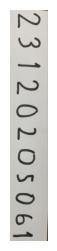

Bulunan rakam sayisi: 1
Tahmin: 1
UYARI: 11 rakam bekleniyordu, 1 bulundu (segmentasyon sorunu olabilir).


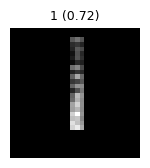

In [10]:
from google.colab import files
uploaded = files.upload()                 # fotografi sec
path = list(uploaded.keys())[0]

OGRENCI_NO = "23120205061"        # ornek: "2021123456"

# Once yuklenen orijinal gorsel
plt.figure(figsize=(8, 3)); plt.imshow(Image.open(path)); plt.axis("off"); plt.show()
predict_number(path, expected=OGRENCI_NO)

## 8. Değerlendirme (kendi yorumunu yaz)
- Train ve validation eğrileri nasıl? Overfitting var mı?
- Test accuracy ile kendi el yazımdaki başarı arasındaki fark neden oluştu? (distribution shift: kalem kalınlığı, eğim, ortalama, arka plan, MLP'nin konum/ölçek duyarlılığı)
- Hangi rakamlar yanlış tahmin edildi, neden?

In [ ]:
# Sonuclari indirmek icin (grafikler + metrikler + model)
!zip -r results.zip results
files.download("results.zip")